# Duman ve Yangın Tespiti – YOLOv8 Denemesi

**Başlamadan önce:** Çalışma zamanı → Çalışma zamanı türünü değiştir → **T4 GPU**

## 1. GPU kontrolü ve kurulum
Çıktıda `Tesla T4` görmelisin.

In [2]:
!nvidia-smi
!pip install -q ultralytics roboflow

Fri Oct 16 18:43:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Veri setini indir
1. [universe.roboflow.com](https://universe.roboflow.com) → **fire smoke detection** ara, birkaç bin görüntülük bir set seç.
2. **Download Dataset → Format: YOLOv8 → Show download code** de.
3. Roboflow'un verdiği kodu aşağıdaki hücrenin yerine yapıştır (API anahtarın onun içinde olur, kimseyle paylaşma).

In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="API_ANAHTARINIZ")
project = rf.workspace("computer-vision-mkpxu").project("fire-n-smoke-detection-wuaqm")
version = project.version(1)
dataset = version.download("yolov8")



Extracting Dataset Version Zip to fire-n-smoke-detection-1 in yolov8:: 100%|██████████| 18028/18028 [00:02<00:00, 8284.92it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
# Veri setinin yolu ve sınıfları
DATA = dataset.location + "/data.yaml"
print(open(DATA).read())

names:
- fire
- smoke
nc: 2
roboflow:
  license: MIT
  project: fire-n-smoke-detection-wuaqm
  url: https://universe.roboflow.com/computer-vision-mkpxu/fire-n-smoke-detection-wuaqm/dataset/1
  version: 1
  workspace: computer-vision-mkpxu
test: ../test/images
train: ../train/images
val: ../valid/images



In [5]:
import yaml, os
cfg = yaml.safe_load(open(DATA))
root = dataset.location
cfg["train"] = os.path.join(root, "train/images")
cfg["val"]   = os.path.join(root, "valid/images")
cfg["test"]  = os.path.join(root, "test/images")
yaml.safe_dump(cfg, open(DATA, "w"))
print(open(DATA).read())

names:
- fire
- smoke
nc: 2
roboflow:
  license: MIT
  project: fire-n-smoke-detection-wuaqm
  url: https://universe.roboflow.com/computer-vision-mkpxu/fire-n-smoke-detection-wuaqm/dataset/1
  version: 1
  workspace: computer-vision-mkpxu
test: /content/fire-n-smoke-detection-1/test/images
train: /content/fire-n-smoke-detection-1/train/images
val: /content/fire-n-smoke-detection-1/valid/images



## 3. Eğitim – YOLOv8n (küçük model)
9 bin görüntüyle 20 epoch, T4'te yaklaşık 30 dk sürdü.

In [6]:
from ultralytics import YOLO
model_n = YOLO("yolov8n.pt")
model_n.train(data=DATA, epochs=20, imgsz=640, batch=16, name="yolov8n_fire")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-n-smoke-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_fire, nbs=64, nms=None, opset=None, op

## 4. Değerlendirme (test seti)
Modelin eğitimde hiç görmediği 903 test görüntüsü üzerinde.

In [7]:
best = YOLO("runs/detect/yolov8n_fire/weights/best.pt")
t = best.val(data=DATA, split="test")
print(f"TEST  mAP@50: {t.box.map50:.3f}  mAP@50-95: {t.box.map:.3f}  P: {t.box.mp:.3f}  R: {t.box.mr:.3f}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1137.0±367.0 MB/s, size: 30.5 KB)
val: Scanning /content/fire-n-smoke-detection-1/test/labels... 903 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 903/903 1.9Kit/s 0.5s
val: New cache created: /content/fire-n-smoke-detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 3.7it/s 15.4s
                   all        903       2171      0.593      0.378      0.428      0.237
                  fire        499       1078      0.509      0.447      0.427      0.208
                 smoke        466       1093      0.678      0.309      0.428      0.267
Speed: 2.0ms preprocess, 4.7ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val
TEST  mAP@50: 0.

## 5. Örnek tahminler
Kendi bulduğun bir yangın fotoğrafını ve **yangın olmayan** bir fotoğrafı (gün batımı, kırmızı ışık vb.) yükleyip dene – yanlış alarm veriyor mu?

Saving gercek_yangin.jpg to gercek_yangin.jpg
Saving sahte_yangin.jpg to sahte_yangin.jpg

image 1/1 /content/gercek_yangin.jpg: 448x640 1 fire, 9.2ms
Speed: 2.1ms preprocess, 9.2ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict
gercek_yangin.jpg → 1 tespit

image 1/1 /content/sahte_yangin.jpg: 480x640 1 fire, 37.3ms
Speed: 2.2ms preprocess, 37.3ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict
sahte_yangin.jpg → 1 tespit


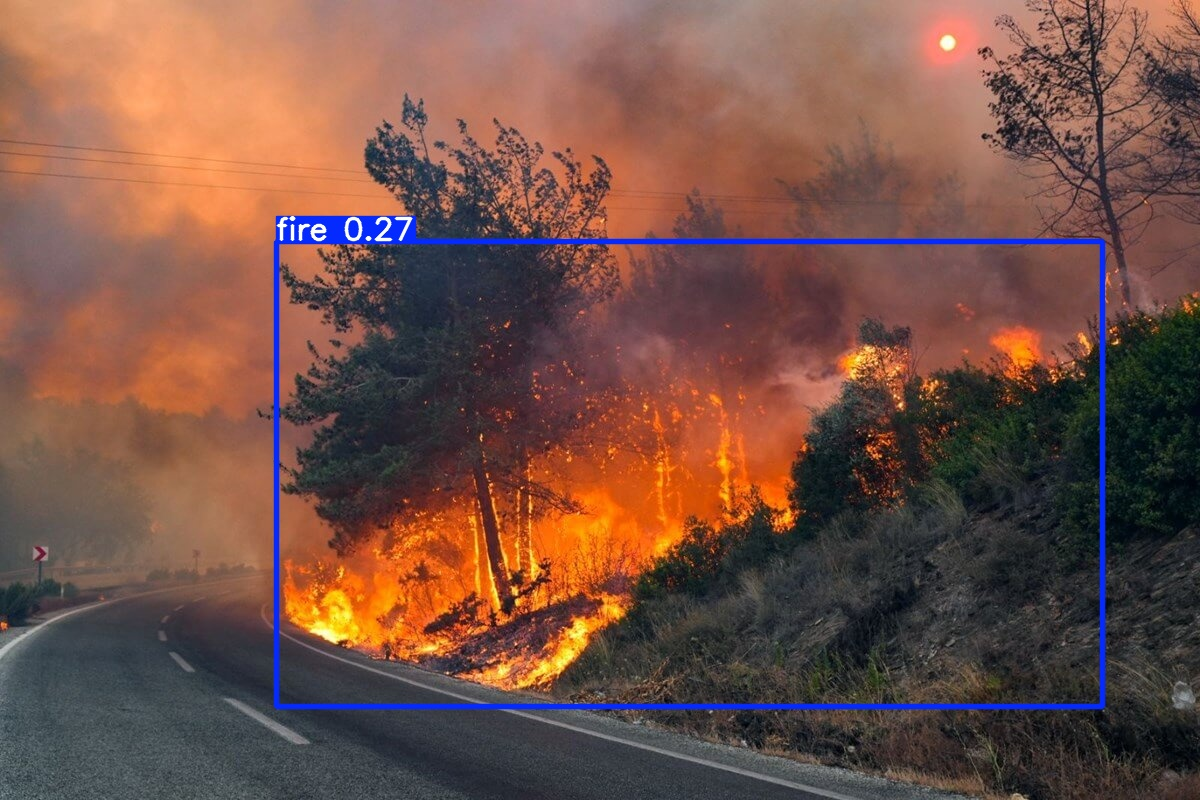

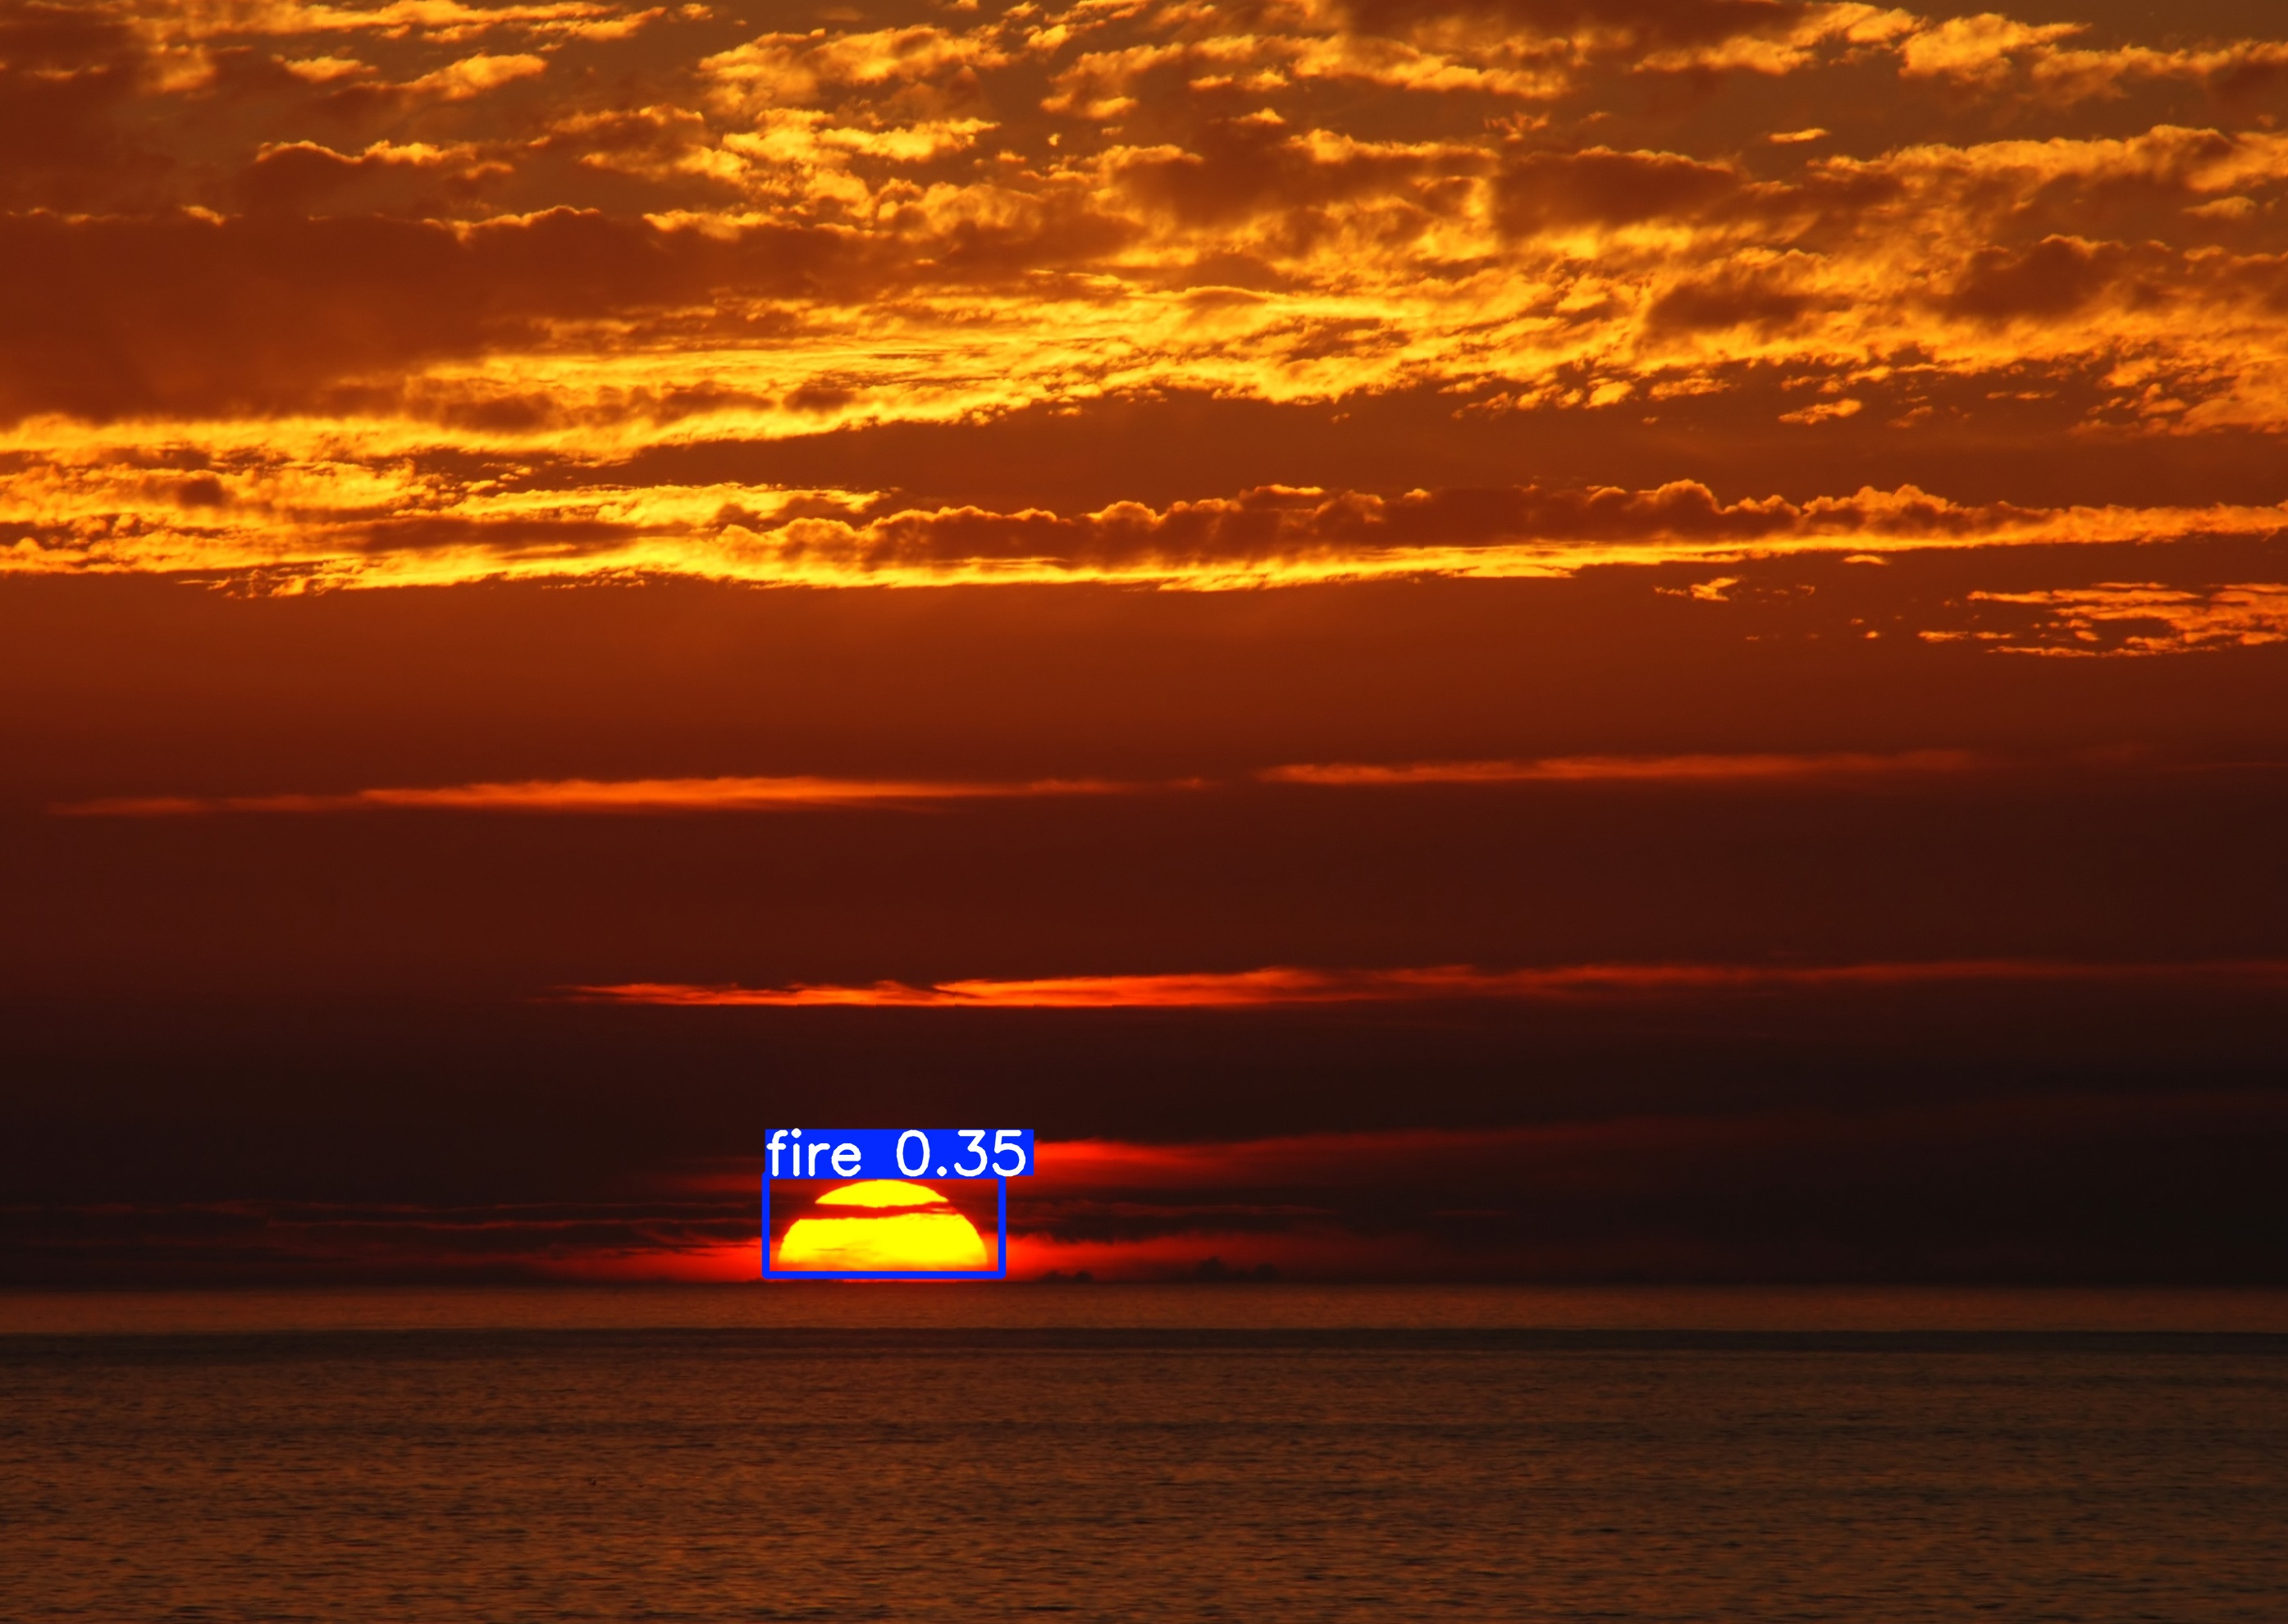

In [8]:
from google.colab import files
up = files.upload()
for f in up:
    r = model_n.predict(f, conf=0.25, save=True)
    print(f, "→", len(r[0].boxes), "tespit")

from IPython.display import Image, display
import glob
for p in sorted(glob.glob("runs/detect/predict*/*"))[-6:]:
    display(Image(p, width=500))

## 6. (İsteğe bağlı) Karşılaştırma – YOLOv8s

In [ ]:
model_s = YOLO("yolov8s.pt")
model_s.train(data=DATA, epochs=30, imgsz=640, batch=16, name="yolov8s_fire")
ms = model_s.val(data=DATA)

print(f"{'Model':10}{'mAP@50':>10}{'mAP@50-95':>12}{'Precision':>11}{'Recall':>9}")
for name, x in [("YOLOv8n", m), ("YOLOv8s", ms)]:
    print(f"{name:10}{x.box.map50:>10.3f}{x.box.map:>12.3f}{x.box.mp:>11.3f}{x.box.mr:>9.3f}")

## 7. Sonuçları indir (GitHub için)

In [ ]:
!zip -qr sonuclar.zip runs/detect
files.download("sonuclar.zip")

In [ ]:
import shutil, glob, os
os.makedirs("github/images", exist_ok=True); os.makedirs("github/results", exist_ok=True)
for p in glob.glob("runs/detect/predict*/*.jpg"):
    shutil.copy(p, "github/images/")
for f in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    src = f"runs/detect/yolov8n_fire/{f}"
    if os.path.exists(src): shutil.copy(src, "github/results/")
shutil.make_archive("github_dosyalari", "zip", "github")
from google.colab import files; files.download("github_dosyalari.zip")